# Методы обработки и распознавания изображений¶

## Практическое занятие 6: Transfer Learning, Adversarial Attacks, Deep Network Visualization

In [1]:
# 0. Импорт библиотек и базовые настройки

import os
import copy
import json
import random
import zipfile
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn, optim
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import ImageFolder
from torchvision.transforms import Compose, Resize, ToTensor, Normalize
from torchvision.models import resnet18
from torch.utils.data import Subset

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", DEVICE)
import torchvision
print("torch version:", torch.__version__)
print("torchvision version:", torchvision.__version__)

Устройство: cpu
torch version: 2.14.0+cpu
torchvision version: 0.29.0+cpu


In [14]:
# 1. Загрузка и подготовка данных Cats/Dogs

DATA_ARCHIVE = Path("kagglecatsanddogs_5340.zip")
DATA_DIR = Path("PetImages")

'''if not DATA_DIR.exists():
    if not DATA_ARCHIVE.exists():
        import urllib.request
        url = (
            "https://download.microsoft.com/download/"
            "3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/"
            "kagglecatsanddogs_5340.zip"
        )
        print("Скачивание архива...")
        urllib.request.urlretrieve(url, DATA_ARCHIVE)

    print("Распаковка архива...")
    with zipfile.ZipFile(DATA_ARCHIVE, "r") as zf:
        zf.extractall(".")'''

# убрать известные испорченные файлы
bad_paths = [
    Path("PetImages/Cat/666.jpg"),
    Path("PetImages/Dog/11702.jpg"),
    Path("readme[1].txt"),
    Path("CDLA-Permissive-2.0.pdf"),
]
for path in bad_paths:
    if path.exists() and path.is_file():
        path.unlink()

print("Каталог данных готов:", DATA_DIR.exists())

# преобразования
transform = Compose([
    Resize((224, 224)),
    ToTensor(),
    Normalize(mean=[0.5, 0.5, 0.5], std=[1.0, 1.0, 1.0]),
])

dataset = ImageFolder(DATA_DIR, transform=transform)

FRACTION = 0.2
n_total = len(dataset)
n_keep = int(n_total * FRACTION)

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(n_total, generator=g)[:n_keep]

small_dataset = Subset(dataset, perm.tolist())

train_size = int(0.8 * len(small_dataset))
val_size = (len(small_dataset) - train_size)

train_set, val_set = random_split(
    small_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED),
)

train_loader = DataLoader(train_set, batch_size=64, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=64, shuffle=False, num_workers=2)

print("Классы:", dataset.classes)
print("Размер обучающей выборки:", len(train_set))
print("Размер валидационной выборки:", len(val_set))

Каталог данных готов: True
Классы: ['Cat', 'Dog']
Размер обучающей выборки: 3999
Размер валидационной выборки: 1000


NameError: name 'train_set' is not defined

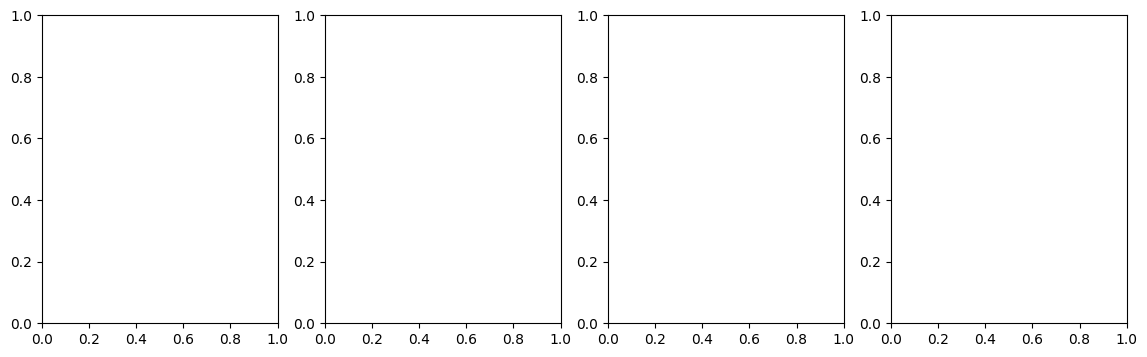

In [2]:
# 2. Просмотр нескольких примеров

def denormalize_image(image_tensor):
    img = image_tensor.detach().cpu().permute(1, 2, 0).numpy()
    img = np.clip(img + 0.5, 0, 1)
    return img

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
indices = np.random.choice(len(train_set), size=4, replace=False)
for ax, idx in zip(axes, indices):
    image, label = train_set[idx]
    ax.imshow(denormalize_image(image))
    ax.set_title(dataset.classes[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [3]:
# 3. Модель ResNet18, TL

class TransferResNet18(nn.Module):
    """
    ResNet18 с предобученными весами ImageNet,
    последний слой адаптирован под 2 класса.
    """
    def __init__(self, num_classes=2):
        super().__init__()
        self.model = resnet18(pretrained=True)  # старый, но рабочий стиль
        in_features = self.model.fc.in_features
        self.model.fc = nn.Linear(in_features, num_classes)

    def forward(self, x):
        return self.model(x)

model = TransferResNet18().to(DEVICE)
criterion = nn.CrossEntropyLoss()
print(model)

TransferResNet18(
  (model): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-

In [4]:
# 4. Заморозка/разморозка слоев ResNet18

def freeze_feature_extractor(model):
    """
    Feature extraction: фиксируем все слои,
    кроме финального полносвязного.
    """
    for param in model.model.parameters():
        param.requires_grad = False
    for param in model.model.fc.parameters():
        param.requires_grad = True


def unfreeze_last_block(model):
    """
    Fine-tuning: размораживаем layer4 и классификатор.
    """
    for name, param in model.model.named_parameters():
        if name.startswith("layer4") or name.startswith("fc"):
            param.requires_grad = True
        else:
            param.requires_grad = False

In [5]:
# 5. Обучение / оценка / история

def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        total_correct += (preds == labels).sum().item()
        total_samples += labels.size(0)

    return total_loss / total_samples, total_correct / total_samples


@torch.no_grad()
def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        total_correct += (preds == labels).sum().item()
        total_samples += labels.size(0)

    return total_loss / total_samples, total_correct / total_samples


def run_training(model, train_loader, val_loader, criterion, optimizer, epochs, stage_name, device):
    """
    Полный цикл обучения, возвращаем историю и лучшую модель по val accuracy.
    """
    history = []
    best_weights = copy.deepcopy(model.state_dict())
    best_val_acc = 0.0

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate(model, val_loader, criterion, device)

        history.append({
            "stage": stage_name,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc,
        })

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_weights = copy.deepcopy(model.state_dict())

        print(
            f"{stage_name} | эпоха {epoch}/{epochs} | "
            f"train_loss={train_loss:.4f} | train_acc={train_acc:.4f} | "
            f"val_loss={val_loss:.4f} | val_acc={val_acc:.4f}"
        )

    model.load_state_dict(best_weights)
    return history

In [16]:
# 6. Этап 1: feature extraction

freeze_feature_extractor(model)
optimizer = optim.Adam(model.model.fc.parameters(), lr=1e-3)

feature_history = run_training(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=3,
    stage_name="Feature extraction",
    device=DEVICE,
)

Feature extraction | эпоха 1/3 | train_loss=0.0967 | train_acc=0.9665 | val_loss=0.0854 | val_acc=0.9690
Feature extraction | эпоха 2/3 | train_loss=0.0765 | train_acc=0.9717 | val_loss=0.0783 | val_acc=0.9680
Feature extraction | эпоха 3/3 | train_loss=0.0716 | train_acc=0.9742 | val_loss=0.0767 | val_acc=0.9670


In [17]:
# 7. Этап 2: fine-tuning

unfreeze_last_block(model)
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-4,
)

fine_history = run_training(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=2,
    stage_name="Fine-tuning",
    device=DEVICE,
)

Fine-tuning | эпоха 1/2 | train_loss=0.0686 | train_acc=0.9722 | val_loss=0.0528 | val_acc=0.9760
Fine-tuning | эпоха 2/2 | train_loss=0.0153 | train_acc=0.9952 | val_loss=0.0519 | val_acc=0.9820


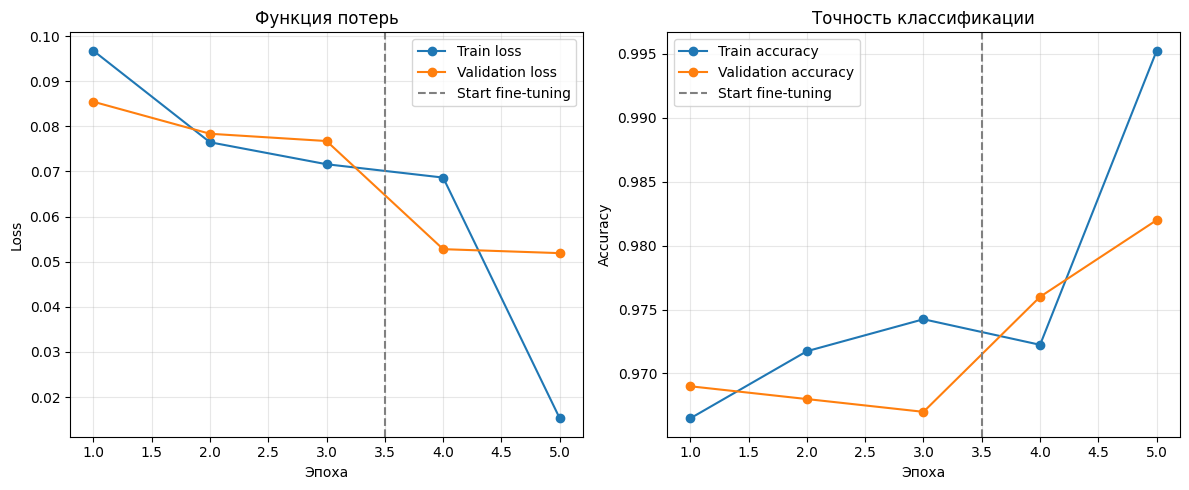

In [18]:
# 8. Визуализация метрик

full_history = feature_history + fine_history

epochs = list(range(1, len(full_history) + 1))
train_loss_values = [h["train_loss"] for h in full_history]
val_loss_values = [h["val_loss"] for h in full_history]
train_acc_values = [h["train_acc"] for h in full_history]
val_acc_values = [h["val_acc"] for h in full_history]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_loss_values, marker="o", label="Train loss")
plt.plot(epochs, val_loss_values, marker="o", label="Validation loss")
plt.axvline(3.5, linestyle="--", color="gray", label="Start fine-tuning")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.title("Функция потерь")
plt.grid(alpha=0.3)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, train_acc_values, marker="o", label="Train accuracy")
plt.plot(epochs, val_acc_values, marker="o", label="Validation accuracy")
plt.axvline(3.5, linestyle="--", color="gray", label="Start fine-tuning")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.title("Точность классификации")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

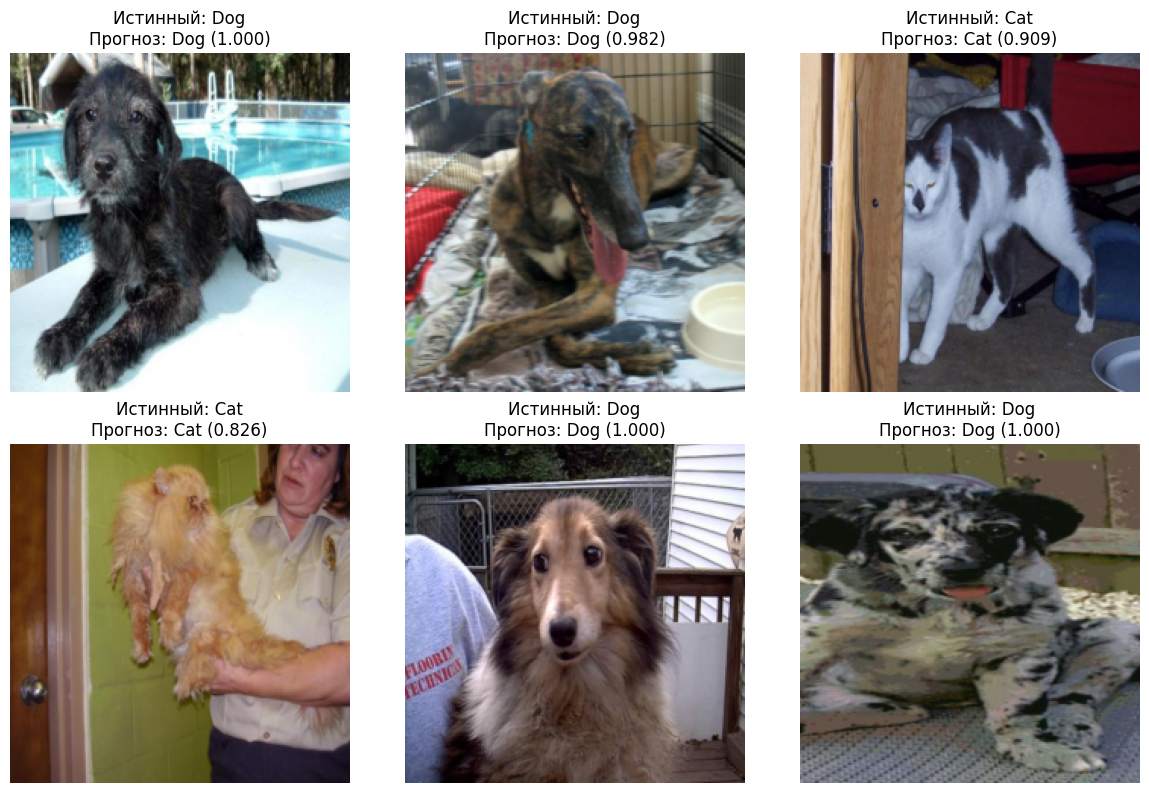

In [19]:
# 9. Примеры предсказаний

@torch.no_grad()
def show_predictions(model, dataset_subset, class_names, device, num_images=6):
    model.eval()
    indices = np.random.choice(len(dataset_subset), size=num_images, replace=False)

    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    axes = axes.ravel()

    for ax, idx in zip(axes, indices):
        image, label = dataset_subset[idx]
        logits = model(image.unsqueeze(0).to(device))
        probs = torch.softmax(logits, dim=1)
        pred = probs.argmax(dim=1).item()
        conf = probs[0, pred].item()

        ax.imshow(denormalize_image(image))
        ax.set_title(
            f"Истинный: {class_names[label]}\n"
            f"Прогноз: {class_names[pred]} ({conf:.3f})"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_predictions(model, val_set, dataset.classes, DEVICE)

In [20]:
# 10. Итоговая оценка и save

val_loss, val_acc = evaluate(model, val_loader, criterion, DEVICE)
print(f"Итоговая ошибка на валидации: {val_loss:.4f}")
print(f"Итоговая точность на валидации: {val_acc:.4f}")

#torch.save(model.state_dict(), "cats_dogs_resnet18_transfer.pth")
#print("Веса сохранены: cats_dogs_resnet18_transfer.pth")

Итоговая ошибка на валидации: 0.0519
Итоговая точность на валидации: 0.9820


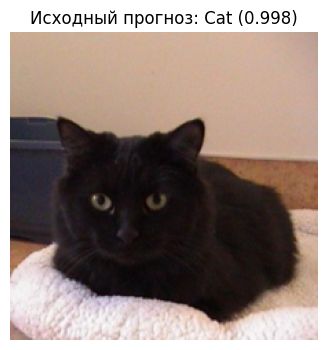

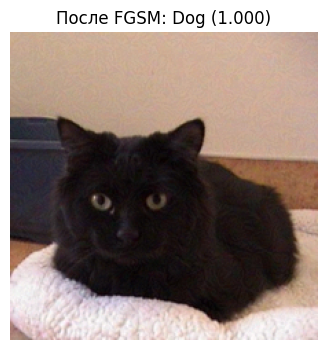

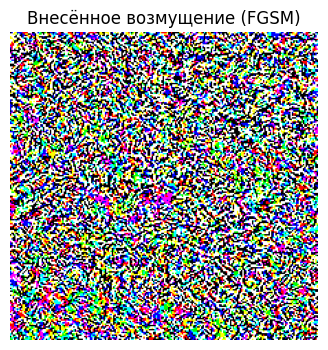

In [21]:
# 11. FGSM-атака

def fgsm_attack(image, epsilon, data_grad):
    signed_grad = data_grad.sign()
    perturbed_image = image + epsilon * signed_grad
    perturbed_image = torch.clamp(perturbed_image, -0.5, 0.5)
    return perturbed_image

# выбираем кошку из train_set
while True:
    idx = np.random.randint(0, len(train_set))
    sample_image, sample_label = train_set[idx]
    if sample_label == dataset.class_to_idx["Cat"]:
        break

image = sample_image.unsqueeze(0).to(DEVICE)
label = torch.tensor([sample_label], device=DEVICE)
image.requires_grad = True

model.eval()
output = model(image)

initial_pred = output.argmax(dim=1).item()
initial_conf = torch.softmax(output, dim=1)[0, initial_pred].item()

plt.figure(figsize=(4, 4))
plt.imshow(denormalize_image(sample_image))
plt.title(f"Исходный прогноз: {dataset.classes[initial_pred]} ({initial_conf:.3f})")
plt.axis("off")
plt.show()

loss = criterion(output, label)
model.zero_grad()
loss.backward()

epsilon = 0.01
perturbed_image = fgsm_attack(image, epsilon, image.grad.data)

with torch.no_grad():
    perturbed_output = model(perturbed_image)
    perturbed_pred = perturbed_output.argmax(dim=1).item()
    perturbed_conf = torch.softmax(perturbed_output, dim=1)[0, perturbed_pred].item()

plt.figure(figsize=(4, 4))
plt.imshow(denormalize_image(perturbed_image.squeeze(0)))
plt.title(f"После FGSM: {dataset.classes[perturbed_pred]} ({perturbed_conf:.3f})")
plt.axis("off")
plt.show()

perturbation = (perturbed_image - image).detach().cpu().squeeze(0).permute(1, 2, 0).numpy()
perturbation = (perturbation - perturbation.min()) / (perturbation.max() - perturbation.min() + 1e-8)

plt.figure(figsize=(4, 4))
plt.imshow(perturbation)
plt.title("Внесённое возмущение (FGSM)")
plt.axis("off")
plt.show()

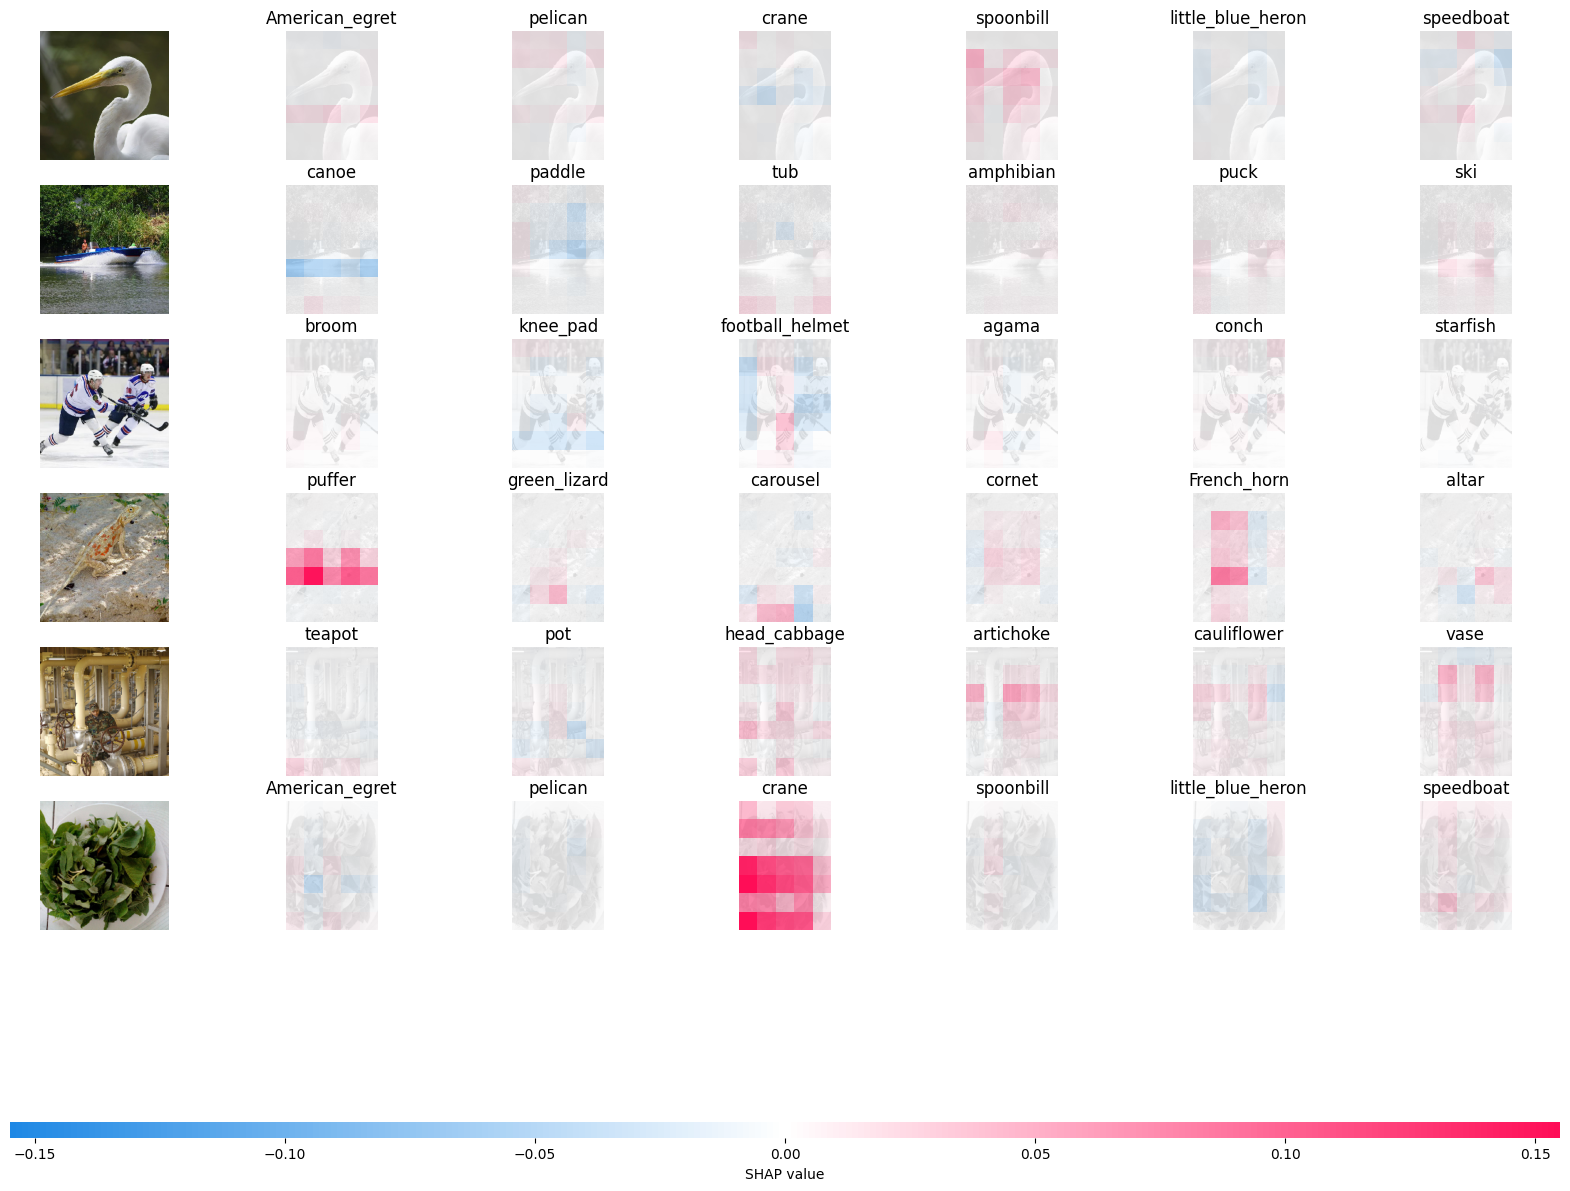

In [27]:
# 12. SHAP для ResNet18

#!pip install shap

import shap

imagenet_model = resnet18(pretrained=True).eval().to(DEVICE)

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

def normalize_for_shap(images_numpy):
    imgs = images_numpy.copy()
    if imgs.max() > 1:
        imgs = imgs / 255.0
    imgs = (imgs - mean) / std
    imgs = np.transpose(imgs, (0, 3, 1, 2))
    return torch.tensor(imgs, dtype=torch.float32).to(DEVICE)

X, y = shap.datasets.imagenet50()
X = X / 255.0
samples_to_explain = X[1:7]

url = "https://s3.amazonaws.com/deep-learning-models/image-models/imagenet_class_index.json"
class_index_path = shap.datasets.cache(url)
with open(class_index_path, "r") as f:
    class_names = json.load(f)

explainer = shap.GradientExplainer(
    (imagenet_model, imagenet_model.layer4[0].conv2),
    normalize_for_shap(X),
)

shap_values, indexes = explainer.shap_values(
    normalize_for_shap(samples_to_explain),
    ranked_outputs=5,
    nsamples=50,
)

index_names = np.vectorize(lambda idx: class_names[str(idx)][1])(indexes)
index_names = np.tile(np.asarray(index_names).ravel(), (len(shap_values), 1))
shap_values = [np.transpose(s, (0, 2, 3, 1)) for s in shap_values]

shap.image_plot(shap_values, samples_to_explain, index_names)